# 05 · Reducción de dimensionalidad: PCA por dimensión y estadístico

**Objetivo.** Resumir cada bloque (4 dimensiones × 3 estadísticos de trayectoria = 12 bloques) en componentes principales interpretables, que sirven de insumo para el clustering (H1) y las regresiones (H2/H3).

**Procedimiento por bloque** (`src/inflacion/pca.py`, `pipeline/run_pca.py`):

1. Eliminar duplicados casi exactos (|r| > 0,99), por ejemplo el mismo índice WGI publicado en dos escalas.
2. Si el bloque tiene más variables que la mitad de los países, podar por redundancia con umbrales decrecientes (0,95 → 0,80), conservando siempre las variables protegidas por la teoría.
3. Eliminar iterativamente la variable de menor MSA hasta alcanzar KMO ≥ 0,60.
4. PCA sobre las features estandarizadas e imputadas. Se retienen los componentes que suman al menos el 70% de la varianza. El signo de cada componente se fija para que su variable de mayor carga sea positiva.

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
import pickle

res = pickle.load(open(D / "pca_resultados.pkl", "rb"))
summary = pd.read_csv(D / "pca_resumen.csv")
meta = pd.concat([pd.read_csv(Paths.raw / "wdi" / "wdi_metadata_20261111.csv"),
                  pd.read_csv(Paths.raw / "vdem" / "vdem_79_metadata_v16.csv")]).drop_duplicates("codigo").set_index("codigo")["nombre_indicador"]
meta["hh_market_concentration"] = "Export market concentration (HHI)"
name = lambda c: meta.get(c.rsplit("__", 1)[0], c.rsplit("__", 1)[0])
summary[["bloque", "n_inicial", "n_post_corr", "n_final", "protegidas", "kmo", "n_comp_70", "var_pc1", "var_acum"]]

,bloque,n_inicial,n_post_corr,n_final,protegidas,kmo,n_comp_70,var_pc1,var_acum
0,MONETARIA_media,59,57,57,5,0.740,9,0.220,0.700
1,MONETARIA_tendencia,59,57,57,5,0.602,13,0.134,0.701
2,MONETARIA_volatilidad,59,57,57,5,0.770,11,0.227,0.701
3,INSTITUCIONAL_media,85,76,76,3,0.906,7,0.462,0.713
4,INSTITUCIONAL_tendencia,85,77,77,3,0.787,14,0.262,0.705
5,INSTITUCIONAL_volatilidad,85,77,77,3,0.855,14,0.297,0.704
6,ESTRUCTURAL_media,168,121,120,4,0.609,20,0.154,0.703
7,ESTRUCTURAL_tendencia,168,135,87,4,0.602,20,0.100,0.702
8,ESTRUCTURAL_volatilidad,168,132,123,4,0.601,25,0.158,0.710
9,SOCIODEMOGRAFICA_media,241,89,89,3,0.873,10,0.342,0.704


## 1. Adecuación muestral y poda

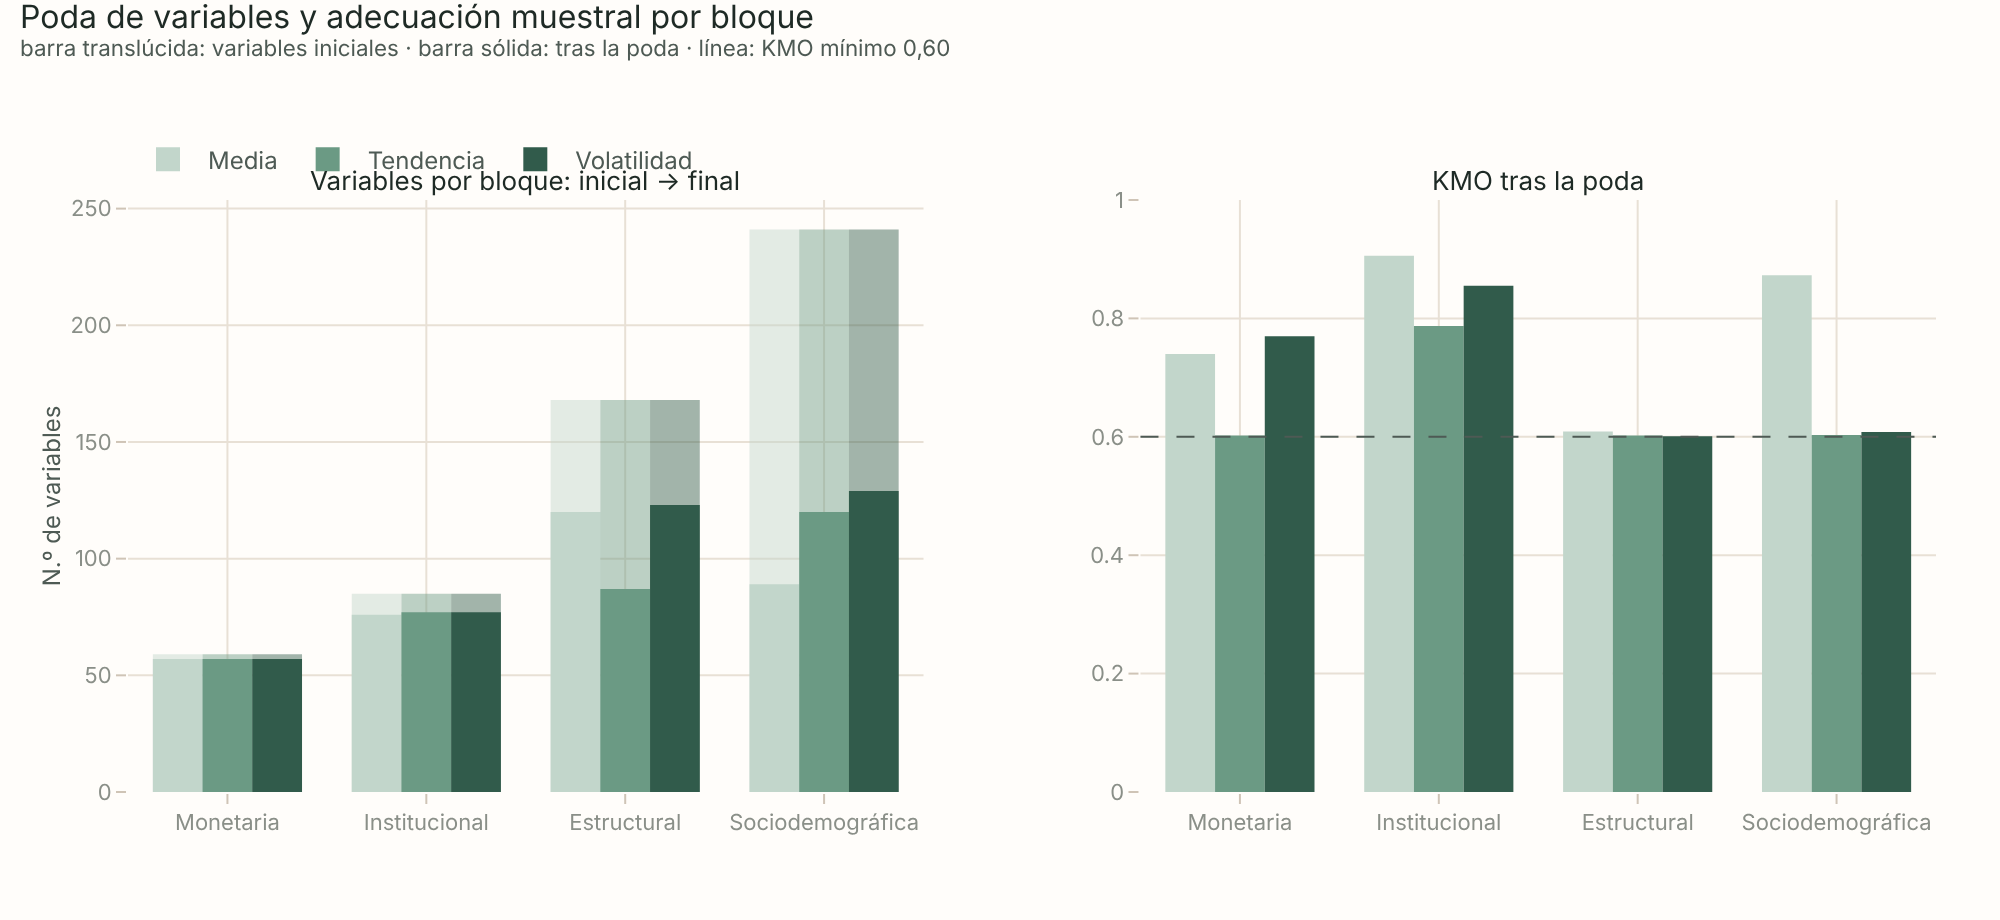

In [2]:
s = summary.copy()
s["dim"] = s["dimension"].map(DIM_LABELS)
fig = make_subplots(rows=1, cols=2, subplot_titles=("Variables por bloque: inicial → final", "KMO tras la poda"), horizontal_spacing=0.12)
for i, stat in enumerate(["media", "tendencia", "volatilidad"]):
    g = s[s["estadistico"] == stat]
    fig.add_bar(x=g["dim"], y=g["n_inicial"], name=f"{stat} · inicial", marker_color=SEQUENTIAL_BLUE[1 + i * 2], opacity=0.45,
                legendgroup=stat, showlegend=False, hovertemplate=stat + " %{x}: %{y} iniciales<extra></extra>", row=1, col=1, offsetgroup=i)
    fig.add_bar(x=g["dim"], y=g["n_final"], name=stat.capitalize(), marker_color=SEQUENTIAL_BLUE[1 + i * 2], legendgroup=stat,
                hovertemplate=stat + " %{x}: %{y} finales<extra></extra>", row=1, col=1, offsetgroup=i)
    fig.add_bar(x=g["dim"], y=g["kmo"], name=stat, marker_color=SEQUENTIAL_BLUE[1 + i * 2], legendgroup=stat, showlegend=False,
                hovertemplate=stat + " %{x}: KMO %{y:.2f}<extra></extra>", row=1, col=2, offsetgroup=i)
fig.add_hline(y=0.6, line=dict(color=INK_SECONDARY, dash="dash", width=1), row=1, col=2)
fig.update_yaxes(title_text="N.º de variables", row=1, col=1)
fig.update_yaxes(range=[0, 1], row=1, col=2)
fig.update_annotations(font_size=13)
fig.update_layout(barmode="overlay", bargap=0.25, title=subtitle("Poda de variables y adecuación muestral por bloque",
                  "barra translúcida: variables iniciales · barra sólida: tras la poda · línea: KMO mínimo 0,60"))
show(fig, "05_poda_kmo", width=1000, height=460)

**Interpretación.** Los 12 bloques quedan con KMO ≥ 0,60 y test de Bartlett significativo (p < 0,001), es decir, con correlaciones suficientes para que el PCA tenga sentido. La poda es fuerte solo en los bloques grandes: la sociodemográfica pasa de 241 a 89-129 variables, y la estructural de 168 a 87-123. Monetaria e institucional apenas pierden sus duplicados. Los bloques de **tendencia** son los de KMO más bajo (alrededor de 0,60): los cambios a lo largo del tiempo están menos sincronizados entre indicadores que los niveles.

## 2. Varianza explicada

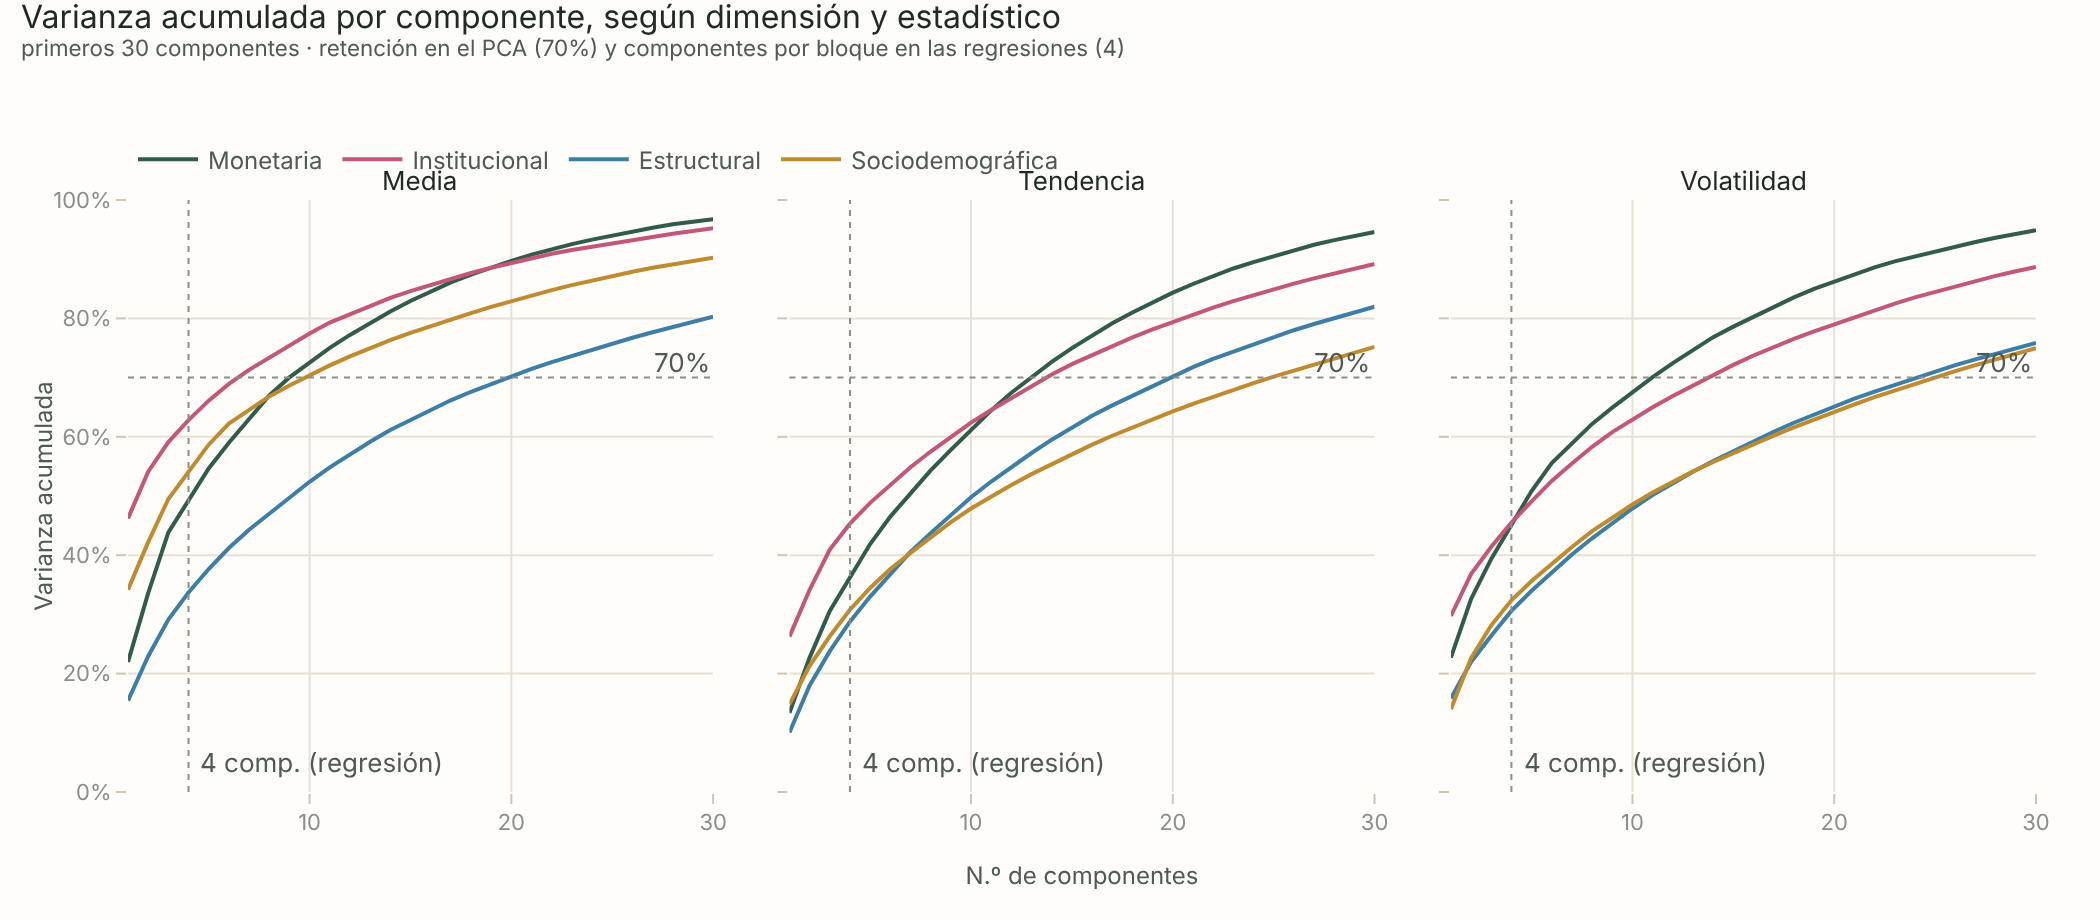

estadistico,media,tendencia,volatilidad
dimension,,,
ESTRUCTURAL,0.337,0.288,0.306
INSTITUCIONAL,0.628,0.453,0.455
MONETARIA,0.493,0.365,0.452
SOCIODEMOGRAFICA,0.542,0.308,0.324


In [3]:
K = P["regresion"]["componentes_por_bloque"]
fig = make_subplots(rows=1, cols=3, subplot_titles=("Media", "Tendencia", "Volatilidad"), shared_yaxes=True, horizontal_spacing=0.04)
for c, stat in enumerate(["media", "tendencia", "volatilidad"], start=1):
    for dim, color in DIMENSION_COLORS.items():
        v = np.cumsum(res[f"{dim}_{stat}"].varianza)[:30]
        fig.add_scatter(x=np.arange(1, len(v) + 1), y=v, mode="lines", name=DIM_LABELS[dim], legendgroup=dim, showlegend=c == 1,
                        line=dict(color=color), hovertemplate=DIM_LABELS[dim] + " · %{x} comp.: %{y:.0%}<extra></extra>", row=1, col=c)
    fig.add_hline(y=0.7, line=dict(color=INK_MUTED, dash="dot", width=1), row=1, col=c)
    fig.add_vline(x=K, line=dict(color=INK_MUTED, dash="dot", width=1), row=1, col=c)
    fig.add_annotation(x=30, y=0.7, text="70%", showarrow=False, xanchor="right", yshift=8, font=dict(size=10, color=INK_SECONDARY), row=1, col=c)
    fig.add_annotation(x=K, y=0.05, text=f"{K} comp. (regresión)", showarrow=False, xanchor="left", xshift=4, font=dict(size=10, color=INK_SECONDARY), row=1, col=c)
fig.update_yaxes(tickformat=".0%", range=[0, 1], row=1, col=1, title_text="Varianza acumulada")
fig.update_xaxes(title_text="N.º de componentes", row=1, col=2)
fig.update_annotations(font_size=13)
fig.update_layout(title=subtitle("Varianza acumulada por componente, según dimensión y estadístico",
                                 f"primeros 30 componentes · retención en el PCA (70%) y componentes por bloque en las regresiones ({K})"))
show(fig, "05_varianza_acumulada", width=1050, height=460)
summary["varianza_regresion"] = [float(np.sum(res[b].varianza[:K])) for b in summary["bloque"]]
summary.pivot(index="dimension", columns="estadistico", values="varianza_regresion").round(3)

**Interpretación.** Las dimensiones redundantes concentran la varianza en pocos componentes: el PC1 institucional explica el 46% de la media y el sociodemográfico el 34%. Las heterogéneas la dispersan: el PC1 estructural explica el 15% y para llegar al 70% hacen falta 20-25 componentes.

Para el **clustering** se usan todos los componentes monetarios retenidos al 70% (33 en total). Para las **regresiones** cada dimensión entra con el **mismo número de componentes (4)**, de modo que las pruebas de H2 comparan bloques con los mismos grados de libertad y el control monetario no queda en desventaja. Cuatro es el máximo que respeta 10 países por predictor (16 predictores para 167 países). La tabla muestra la varianza que capturan: entre el 29% y el 63% según el bloque.

**Por qué no un piso de varianza.** Una versión anterior usaba en cada bloque los componentes necesarios para llegar al 30% de la varianza. Con esa regla el bloque monetario entraba con 2 componentes y el estructural con 4: la dimensión con más componentes tenía más chances de resultar significativa, y el control monetario quedaba débil. Igualar el número de componentes elimina esa ventaja; la sensibilidad a 2 y 3 componentes se muestra en el notebook 08.

## 3. ¿Qué miden los componentes?

Cargas (correlación entre variable y componente) de las 6 variables con mayor carga absoluta en los dos primeros componentes de cada bloque de **media**. Las de tendencia y volatilidad están en `data/processed/pca_resultados.pkl`.

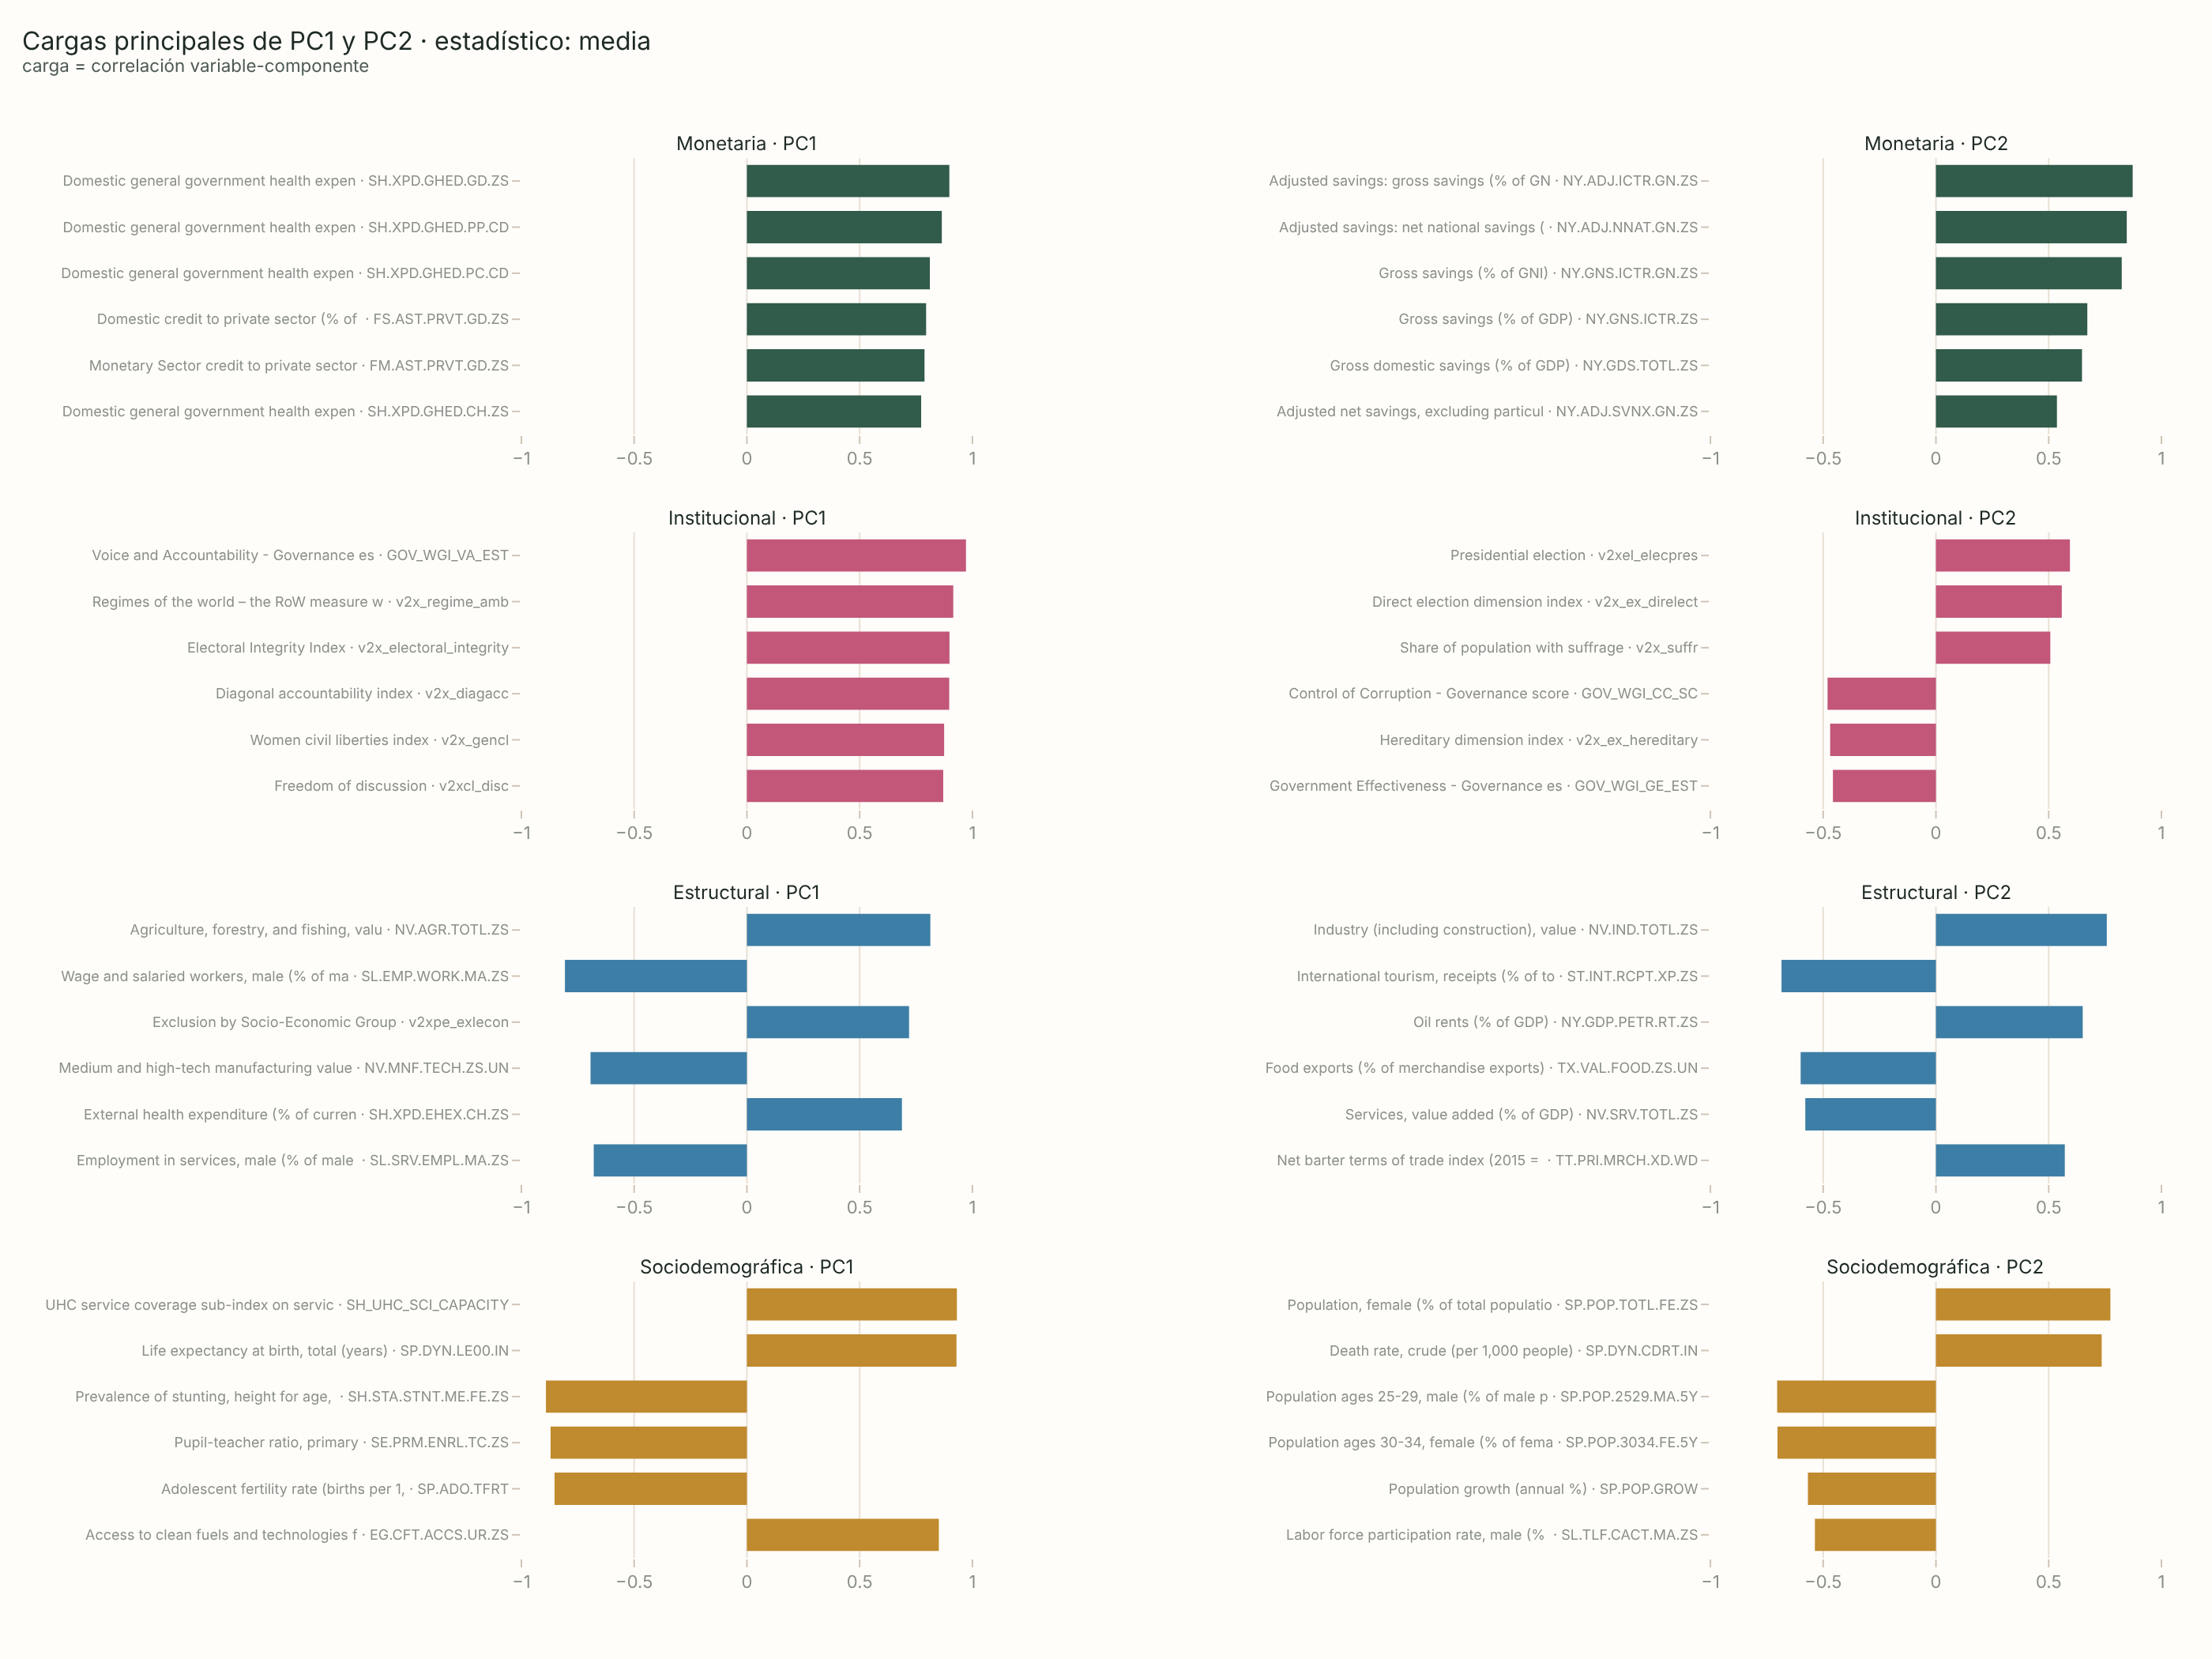

MONETARIA: PC1 22.0% · PC2 11.6%
INSTITUCIONAL: PC1 46.2% · PC2 7.9%
ESTRUCTURAL: PC1 15.4% · PC2 7.5%
SOCIODEMOGRAFICA: PC1 34.2% · PC2 8.0%


In [4]:
def loading_panel(stat, n=6):
    fig = make_subplots(rows=4, cols=2, horizontal_spacing=0.45, vertical_spacing=0.07,
                        subplot_titles=[f"{DIM_LABELS[d]} · PC{k}" for d in DIMENSION_COLORS for k in (1, 2)])
    for r, dim in enumerate(DIMENSION_COLORS, start=1):
        b = res[f"{dim}_{stat}"]
        for k in (1, 2):
            L = b.cargas[f"{dim}_{stat}__PC{k}"]
            top = L.reindex(L.abs().sort_values(ascending=False).index[:n])[::-1]
            labels = [f"{name(i)[:40]} · {i.rsplit('__', 1)[0]}" for i in top.index]
            fig.add_bar(x=top.values, y=labels, orientation="h", marker_color=DIMENSION_COLORS[dim],
                        showlegend=False, hovertemplate="%{y}: %{x:.2f}<extra></extra>", row=r, col=k)
            fig.update_xaxes(range=[-1, 1], row=r, col=k)
            fig.update_yaxes(showgrid=False, tickfont=dict(size=9), row=r, col=k)
    fig.update_annotations(font_size=12)
    fig.update_layout(title=subtitle(f"Cargas principales de PC1 y PC2 · estadístico: {stat}", "carga = correlación variable-componente"),
                      margin=dict(l=330), bargap=0.3)
    return fig

show(loading_panel("media"), "05_cargas_media", width=1400, height=1050)
for dim in DIMENSION_COLORS:
    b = res[f"{dim}_media"]
    print(f"{dim}: PC1 {b.varianza[0]:.1%} · PC2 {b.varianza[1]:.1%}")

**Interpretación de los componentes de nivel (media 2000-2020).**

- **Monetaria PC1 (22%)**: gasto público en salud (cuatro versiones del mismo indicador) y profundidad del crédito al sector privado. Mide **capacidad fiscal y profundidad financiera**, que crecen con el nivel de desarrollo. **Monetaria PC2 (12%)**: tasas de ahorro nacional frente a consumo, o sea, el balance entre ahorro y absorción.
- **Institucional PC1 (46%)**: voz y rendición de cuentas, integridad electoral, libertades civiles. Es un eje **democracia-autocracia**. El PC2 (8%) separa los regímenes presidenciales con elección directa de los de mejor gobernanza administrativa.
- **Estructural PC1 (16%)**: agro y exclusión socioeconómica en un polo; asalariamiento, manufactura de media y alta tecnología y servicios en el otro. Es un eje de **modernización productiva**. El PC2 (7%) contrapone las economías de turismo, servicios y exportación de alimentos a las industriales y petroleras.
- **Sociodemográfica PC1 (34%)**: esperanza de vida y cobertura de salud frente a desnutrición infantil y fecundidad adolescente. Es un eje de **desarrollo humano**. El PC2 (8%) refleja la estructura de edades y la composición por sexo (por ejemplo, la mano de obra migrante masculina de los países del Golfo).

**Advertencia.** El PC1 monetario lo dominan indicadores de gasto público en salud, que el codebook asigna a la dimensión monetaria por su regla de "variables fiscales en sentido amplio". La consecuencia es que el perfil monetario lleva consigo buena parte del gradiente de desarrollo (ver la sección 4). Una mejora posible es acotar esa regla al gasto y el financiamiento agregados (déficit, deuda, consumo público total) y excluir el gasto sectorial.

In [5]:
for stat in ["tendencia", "volatilidad"]:
    for dim in DIMENSION_COLORS:
        L = res[f"{dim}_{stat}"].cargas[f"{dim}_{stat}__PC1"]
        top = L.reindex(L.abs().sort_values(ascending=False).index[:4])
        print(f"{dim}_{stat} PC1 ({res[f'{dim}_{stat}'].varianza[0]:.0%}):", "; ".join(f"{name(i)[:45]} ({v:+.2f})" for i, v in top.items()))

MONETARIA_tendencia PC1 (13%): Gross savings (% of GDP) (+0.87); Adjusted savings: net national savings (% of  (+0.80); Adjusted savings: gross savings (% of GNI) (+0.79); Revenue, excluding grants (% of GDP) (+0.72)
INSTITUCIONAL_tendencia PC1 (26%): Electoral Integrity Index (+0.91); Diagonal accountability index (+0.90); Alternative sources of information index (+0.86); Horizontal accountability index (+0.85)
ESTRUCTURAL_tendencia PC1 (10%): Merchandise imports from low- and middle-inco (+0.73); Adjusted savings: natural resources depletion (+0.72); Merchandise imports from low- and middle-inco (-0.69); Industry (including construction), value adde (+0.69)
SOCIODEMOGRAFICA_tendencia PC1 (15%): Fixed broadband subscriptions (per 100 people (+0.80); UHC service coverage index (-0.73); Lifetime risk of maternal death (%) (+0.71); Mortality rate, neonatal (per 1,000 live birt (+0.71)
MONETARIA_volatilidad PC1 (23%): Adjusted savings: gross savings (% of GNI) (+0.81); Adjusted savings: n

## 4. Correlación entre dimensiones

Si los primeros componentes de dimensiones distintas estuvieran casi perfectamente correlacionados, separar el análisis por dimensiones sería ilusorio. La matriz muestra las correlaciones entre los PC1 de los 12 bloques.

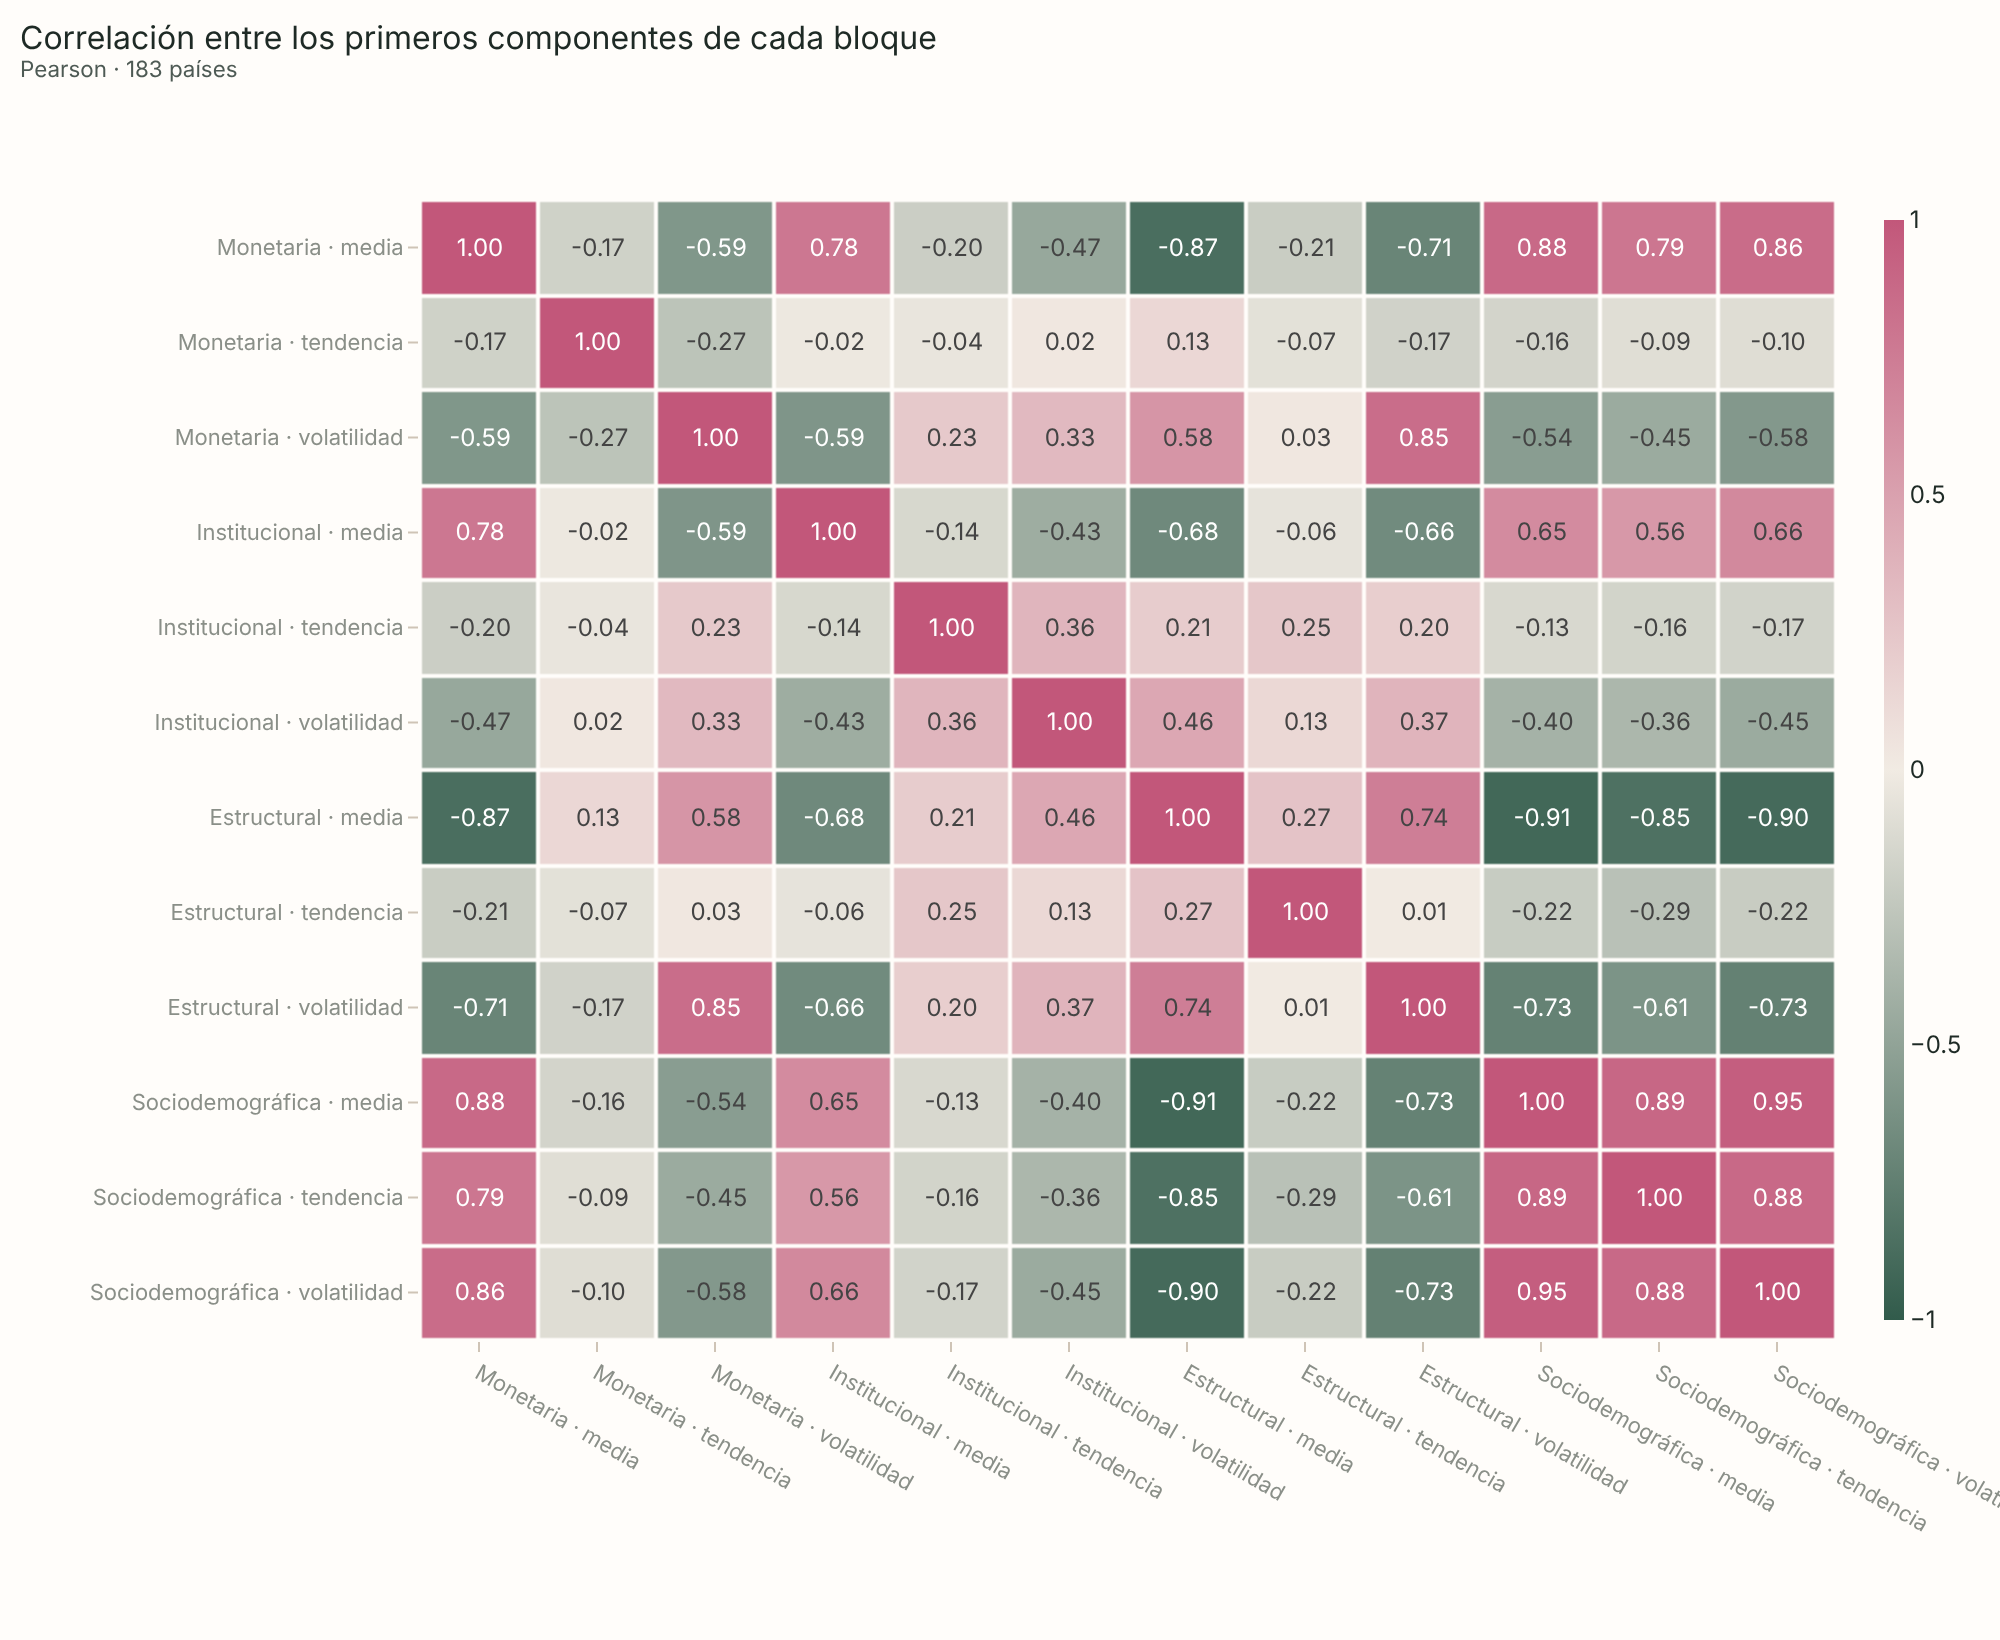

Máx |r| entre PC1 de bloques distintos: 0.95 · ('Sociodemográfica · media', 'Sociodemográfica · volatilidad')
Pares con |r| > 0,7: 16


In [6]:
scores = pd.read_parquet(D / "pca_scores.parquet")
pc1 = scores[[c for c in scores.columns if c.endswith("__PC1")]]
lab = {c: f"{DIM_LABELS[c.split('_')[0]]} · {c.split('_')[1].split('__')[0]}" for c in pc1.columns}
C = pc1.corr().rename(index=lab, columns=lab)
fig = heatmap(C, subtitle("Correlación entre los primeros componentes de cada bloque", "Pearson · 183 países"),
              colorscale=DIVERGING, zmid=0, zmin=-1, zmax=1, fmt=".2f")
fig.update_layout(margin=dict(l=210, b=150))
show(fig, "05_correlacion_pc1", width=1000, height=820)
off = C.where(~np.eye(len(C), dtype=bool)).abs().stack()
print("Máx |r| entre PC1 de bloques distintos:", off.max().round(2), "·", off.idxmax())
print("Pares con |r| > 0,7:", (off > 0.7).sum() // 2)

**Interpretación.** Los PC1 de nivel (media) y de volatilidad de las cuatro dimensiones están fuertemente correlacionados: monetaria-sociodemográfica 0,88, estructural-sociodemográfica −0,91, monetaria-estructural −0,87. Todos comparten un **gradiente de desarrollo**. Hay 16 pares de bloques con |r| > 0,7. Los componentes de **tendencia** tienen correlaciones débiles entre sí (|r| ≤ 0,29), con una excepción: el PC1 de tendencia sociodemográfica sigue de cerca al nivel de desarrollo (r = 0,89 con el PC1 sociodemográfico de media), porque lo dominan indicadores que crecen más rápido donde el nivel ya es alto (banda ancha, cobertura sanitaria).

**Implicancias para las hipótesis.**

1. Controlar por el perfil monetario no es neutral: buena parte de lo que las otras dimensiones tienen en común con la inflación ya entra a través del bloque monetario. Las pruebas de H2 y H3 son, por eso, **conservadoras**: miden el aporte que no comparte el gradiente de desarrollo.
2. La colinealidad entre los PC1 de distintas dimensiones va a elevar los VIF del modelo completo. Por eso en el notebook 07 se reportan los diagnósticos y la inferencia robusta.